# Gaussian Process Regression Example
Following example outlined in SciKit Learns library for GPR. Using data from low fidelity kriging to compare.

\begin{equation}
    k(x_i, x_j) = \exp\left(- \frac{d(x_i, x_j)^2}{2l^2} \right)
\end{equation}

In [41]:
%reload_ext autoreload
%autoreload 2

import os
import sys
module_path = os.path.abspath(os.path.join('SurrogateModels')) # or the path to your source code
sys.path.append(module_path)

In [42]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel

1.0


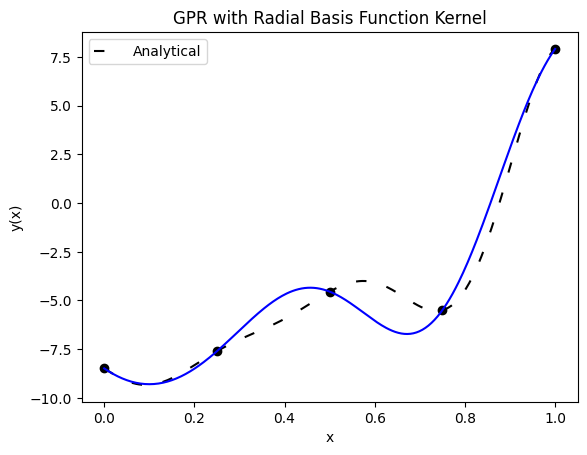

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from SurrogateModels import mfs_functions, kriging

# Start with a synthetic dataset
#rng = np.random.RandomState(0)
fxn_ind = 1
dim,xmin,xmax=mfs_functions.function_bounds(fxn_ind)

n = 5

x = np.zeros((n,dim), dtype=float)

# Generate the analytical functions
lf_fxn = mfs_functions.cheap_fxn(1)

x[:,0] = np.linspace(xmin,xmax,n)
#Randomly changing x[3] from 0.3 to 0.35 fixes problem????
#x[3,0] = 0.35
np.random.shuffle(x[:,0])
y = lf_fxn.evaluate(x)

kernel = ConstantKernel() * RBF()
#gpr = GaussianProcessRegressor(kernel = kernel,random_state=0,optimizer=sk)
gpr.fit(x,y)

x_vals = np.ones((300,1))
x_vals[:,0] = np.linspace(0,1,300)

[y_out,std] = gpr.predict(x_vals[:,:],return_std=True)
score = gpr.score(x_vals,y_out)
print(score)

#model = kriging.Kriging(x,y,1)

#filename = "OutMatrices" + str(n)
#model.print_model_params(filename)

plot_name = "GPR with Radial Basis Function Kernel"
lf_fxn.plot_model(x_vals,plot_name, color = "black",
                  linestyle = (0, (5, 10)), label = "Analytical")
plt.scatter(x,y,color = "black")
# model.plot_data(plot_name, color ="black", 
#                 label = "Samples", marker = '^')
plt.plot(x_vals,y_out, color = "blue",label = "SKLearn")
plt.show()

In [44]:
import pykrige

